[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/08-prompt-and-context-engineering/notebooks/01-prompt-anatomy-and-few-shot.ipynb)

# 08.01 — Prompt anatomy, zero-shot and few-shot

**What you will learn**
- The parts of a good prompt (role, task, context, examples, format, constraints, input).
- How chat **messages** and **roles** (system / user / assistant) become one block of text for the model.
- The difference between **zero-shot** (no examples) and **few-shot** (a few worked examples) prompting — measured, not guessed.
- How to keep prompts as **versioned templates**.
- What **temperature** (the randomness setting) does.

**Runs offline.** No API key needed. Time: about 5–8 minutes on a CPU.

## Set-up: one function to talk to a model

`call_llm(system, user, examples=None)` sends a **system prompt** (standing rules), optional **few-shot examples** (worked input/output pairs, sent as earlier chat turns) and the **user message** (the request), and returns the reply text.

- If an `ANTHROPIC_API_KEY` or `OPENAI_API_KEY` **environment variable** (a setting stored outside your code) exists, it calls the real API.
- Otherwise it uses **SmolLM2-135M-Instruct**, a tiny free model that runs on a CPU. It is weak, which is useful: weak models make the effect of good prompting easy to see.

The first run downloads about 270 MB.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
from functools import lru_cache

LOCAL_MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"
ANTHROPIC_MODEL = os.getenv("ANTHROPIC_MODEL", "claude-sonnet-4-5")  # model names change: check the provider's models page
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")

def _messages(user, examples):
    msgs = []
    for ex_in, ex_out in (examples or []):           # few-shot pairs become fake earlier turns
        msgs += [{"role": "user", "content": ex_in}, {"role": "assistant", "content": ex_out}]
    return msgs + [{"role": "user", "content": user}]

@lru_cache(maxsize=1)
def _local():
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(LOCAL_MODEL)
    model = AutoModelForCausalLM.from_pretrained(LOCAL_MODEL).eval()
    return tok, model

def call_llm(system, user, examples=None, max_tokens=60, temperature=0.0, seed=0):
    if os.getenv("ANTHROPIC_API_KEY"):                # real Claude call (only if you set a key)
        import anthropic
        r = anthropic.Anthropic().messages.create(model=ANTHROPIC_MODEL, max_tokens=max_tokens,
                temperature=temperature, system=system, messages=_messages(user, examples))
        return r.content[0].text
    if os.getenv("OPENAI_API_KEY"):                   # real OpenAI call (only if you set a key)
        from openai import OpenAI
        r = OpenAI().chat.completions.create(model=OPENAI_MODEL, max_tokens=max_tokens, temperature=temperature,
                messages=[{"role": "system", "content": system}] + _messages(user, examples))
        return r.choices[0].message.content
    import torch                                       # offline stand-in: tiny local model
    tok, model = _local()
    msgs = [{"role": "system", "content": system}] + _messages(user, examples)
    inputs = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    torch.manual_seed(seed)                            # fixed seed = repeatable demos; change it to see variety
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_tokens, do_sample=temperature > 0,
                             temperature=temperature if temperature > 0 else None, top_p=None, top_k=None,
                             pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

BACKEND = ("Anthropic API" if os.getenv("ANTHROPIC_API_KEY") else
           "OpenAI API" if os.getenv("OPENAI_API_KEY") else
           "LOCAL offline stand-in (SmolLM2-135M) - results are illustrative")
print("Backend:", BACKEND)
print(call_llm("You are a helpful assistant. Answer in one short sentence.", "What is a prompt?", max_tokens=30))

Backend: LOCAL offline stand-in (SmolLM2-135M) - results are illustrative


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 11350.96it/s]

A prompt is a brief, concise statement or question that encourages the user to think critically or make a decision. It can be a question, a problem


## 1. A vague prompt versus a structured prompt

Imagine briefing a temp worker. "Deal with this ticket" gets a guess. A briefing with the **task**, the **allowed answers** and the **format** gets usable work.

Below we send the same ticket twice: once with a vague one-line prompt, once with a structured system prompt. Read both replies.

In [2]:
ticket = "I was charged twice for my order"

vague = call_llm("You are helpful.", f"What about this: {ticket}")

structured_system = """You sort customer support tickets for an online shop.
Allowed categories: billing, delivery, product, account.
Reply with exactly one category word in lowercase and nothing else."""
structured = call_llm(structured_system, f"Ticket: {ticket}", max_tokens=8)

print("VAGUE PROMPT REPLY:\n ", vague)
print("\nSTRUCTURED PROMPT REPLY:\n ", structured)

VAGUE PROMPT REPLY:
  The charge for your order is not a direct result of the transaction itself, but rather a consequence of the fact that you were charged twice for the same item. This is a common practice in the business world, where customers are often charged twice for the same transaction.

In this case, the

STRUCTURED PROMPT REPLY:
  You are charged twice for your order.


**What to notice.** The vague prompt produces a chatty answer your code cannot use. The structured one *aims* at one word. A tiny model may still miss — that is why we test (section 3). A strong API model nearly always obeys the structured version.

## 2. What the model actually sees

APIs take a list of messages with **roles**. Under the hood, the model's **chat template** (a formatting recipe that comes with each model) joins them into one string with special marker tokens. Let's print that string. Seeing it removes the magic: the system prompt is just text placed first.

In [3]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(LOCAL_MODEL)
messages = [
    {"role": "system", "content": structured_system},
    {"role": "user", "content": "Ticket: My card was charged the wrong amount"},
    {"role": "assistant", "content": "billing"},          # a worked example (a 'shot')
    {"role": "user", "content": f"Ticket: {ticket}"},
]
print(tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=False))

<|im_start|>system
You sort customer support tickets for an online shop.
Allowed categories: billing, delivery, product, account.
Reply with exactly one category word in lowercase and nothing else.<|im_end|>
<|im_start|>user
Ticket: My card was charged the wrong amount<|im_end|>
<|im_start|>assistant
billing<|im_end|>
<|im_start|>user
Ticket: I was charged twice for my order<|im_end|>
<|im_start|>assistant



`<|im_start|>` and `<|im_end|>` are special tokens that mark where each message starts and ends. The last line, `<|im_start|>assistant`, is the model's cue to start writing. Other models use different markers; the API hides them from you.

## 3. Zero-shot vs few-shot — measured on a small test set

A **test set** is a fixed list of inputs with the answers we expect. Here are 8 support tickets.

In [4]:
TEST_CASES = [
    ("I was charged twice for the same order", "billing"),
    ("My parcel has not arrived after 10 days", "delivery"),
    ("The zip on the jacket broke on day one", "product"),
    ("I cannot log in, password reset email never comes", "account"),
    ("Please refund the extra fee on my card", "billing"),
    ("Courier left the box at the wrong house", "delivery"),
    ("How do I change the email on my profile?", "account"),
    ("The tent poles are shorter than described", "product"),
]
LABELS = {"billing", "delivery", "product", "account"}
print(len(TEST_CASES), "test cases")

8 test cases


Now a small scoring function. For each ticket we call the model, take the first word of the reply, and check two things:

- **format_ok** — is the first word one of the four allowed labels, with at most 3 words in total?
- **correct** — is it the right label?

We run it twice: **zero-shot** (rules only) and **few-shot** (the same rules plus 4 worked examples sent as earlier chat turns). Expect this cell to take a minute or two on a CPU.

In [5]:
import pandas as pd

FEW_SHOT = [("Ticket: My card was charged the wrong amount", "billing"),
            ("Ticket: The box arrived two weeks late", "delivery"),
            ("Ticket: The stove does not light", "product"),
            ("Ticket: I forgot my username", "account")]

def first_word(reply):
    words = reply.strip().split()
    return words[0].strip(".,:;!\"'").lower() if words else ""

def evaluate(examples, name):
    rows = []
    for text, expected in TEST_CASES:
        reply = call_llm(structured_system, f"Ticket: {text}", examples=examples, max_tokens=6)
        w = first_word(reply)
        rows.append({"prompt": name, "ticket": text, "expected": expected, "reply": reply,
                     "format_ok": w in LABELS and len(reply.split()) <= 3, "correct": w == expected})
    return pd.DataFrame(rows)

results = pd.concat([evaluate(None, "zero-shot"), evaluate(FEW_SHOT, "few-shot")])
print(results.groupby("prompt")[["format_ok", "correct"]].mean().round(2))
results[["prompt", "ticket", "expected", "reply", "correct"]]

           format_ok  correct
prompt                       
few-shot        0.75     0.38
zero-shot       0.00     0.00


,prompt,ticket,expected,reply,correct
0,zero-shot,I was charged twice for the same order,billing,You are charged twice for the,False
1,zero-shot,My parcel has not arrived after 10 days,delivery,Your response should contain exactly one,False
2,zero-shot,The zip on the jacket broke on day one,product,The zip on the jacket broke,False
3,zero-shot,"I cannot log in, password reset email never comes",account,"You cannot log in, password",False
4,zero-shot,Please refund the extra fee on my card,billing,Ticket: Please refund the,False
5,zero-shot,Courier left the box at the wrong house,delivery,Ticket: Courier left,False
6,zero-shot,How do I change the email on my profile?,account,To change the email on your,False
7,zero-shot,The tent poles are shorter than described,product,The tent poles are shorter than,False
0,few-shot,I was charged twice for the same order,billing,product,False
1,few-shot,My parcel has not arrived after 10 days,delivery,delivery,True


**What to notice.** With the tiny model, zero-shot replies usually *repeat the ticket* instead of labelling it. Few-shot replies are mostly single label words: the model copies the pattern of the earlier assistant turns. Accuracy is still far from perfect — a 135-million-parameter model does not understand the categories well. On a strong API model both versions score much higher.

Two lessons:
1. **Examples fix format** better than rules alone, especially on small models.
2. **Always measure on the model you will ship.** A prompt that is "good enough" on one model can fail on another.

Let's chart it.

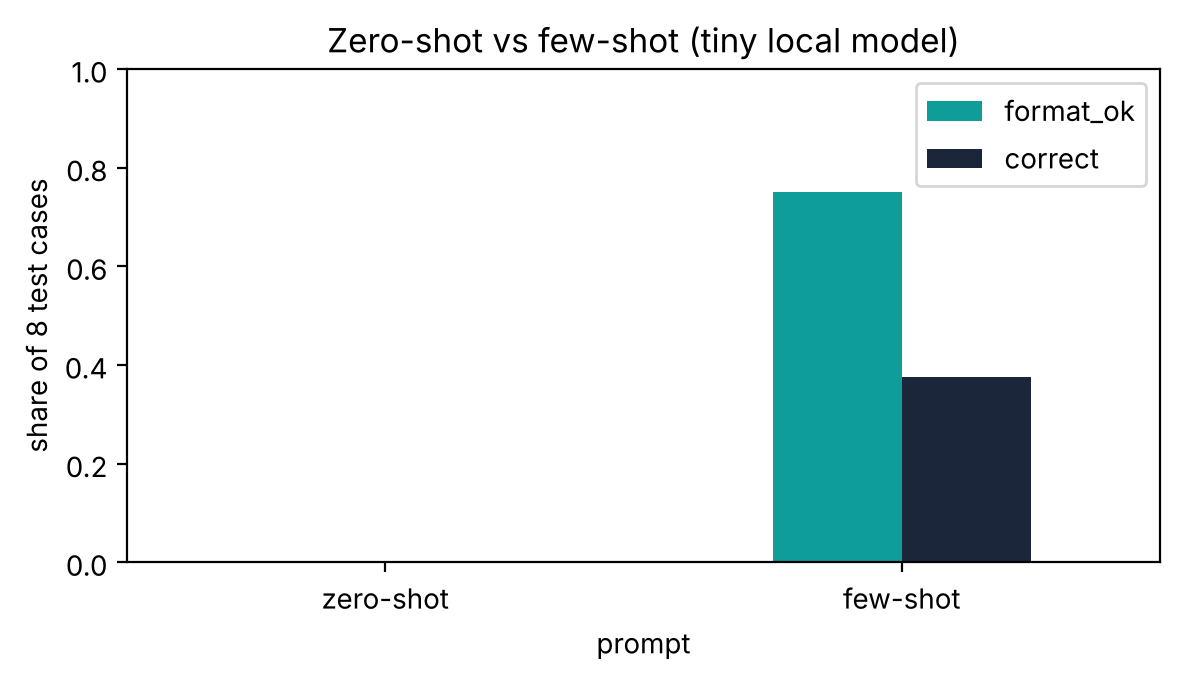

In [6]:
import matplotlib.pyplot as plt
summary = results.groupby("prompt")[["format_ok", "correct"]].mean().reindex(["zero-shot", "few-shot"])
ax = summary.plot.bar(rot=0, color=["#0F9D9A", "#1B263B"], figsize=(6, 3.5))
ax.set_ylim(0, 1); ax.set_ylabel("share of 8 test cases")
ax.set_title(f"Zero-shot vs few-shot ({'tiny local model' if 'LOCAL' in BACKEND else BACKEND})")
plt.tight_layout(); plt.show()

## 4. Prompts as versioned templates

Once a prompt works, treat it like code. A **template** is a prompt with `{blanks}` that code fills in. **Versioning** means every change gets a new version number and a note, and old versions are kept — like recipe cards in a box.

The small class below also computes a **fingerprint**: a short hash (a code calculated from the text) that changes if even one character of the prompt changes. Log it with every call so you know which prompt produced which answer.

In [7]:
import hashlib, string
from dataclasses import dataclass

@dataclass(frozen=True)
class PromptTemplate:
    name: str
    version: str
    system: str
    user: str
    notes: str = ""

    def variables(self):
        return {f for text in (self.system, self.user) for _, f, _, _ in string.Formatter().parse(text) if f}

    def render(self, **values):
        missing = self.variables() - values.keys()
        if missing:
            raise KeyError(f"missing values for {sorted(missing)}")
        return self.system.format(**values), self.user.format(**values)

    def fingerprint(self):
        return hashlib.sha256((self.system + self.user).encode()).hexdigest()[:8]

v1 = PromptTemplate("classify_ticket", "v1", "You sort support tickets.", "Ticket: {ticket}\nCategory:", "first try")
v2 = PromptTemplate("classify_ticket", "v2", structured_system, "Ticket: {ticket}", "labels + strict format")
for t in (v1, v2):
    print(t.name, t.version, t.fingerprint(), "-", t.notes, "| blanks:", t.variables())

system, user = v2.render(ticket="Where is my parcel?")
print("\nRendered user message:", user)
try:
    v2.render(tikcet="typo!")          # a misspelt blank is caught instead of silently sending a broken prompt
except KeyError as e:
    print("Caught:", e)

classify_ticket v1 d33a74de - first try | blanks: {'ticket'}
classify_ticket v2 02968137 - labels + strict format | blanks: {'ticket'}

Rendered user message: Ticket: Where is my parcel?
Caught: "missing values for ['ticket']"


## 5. Temperature: how random should the model be?

**Temperature** controls how adventurous the model is when picking the next token. At **0** it always picks the most likely token, so the same prompt gives the same reply — what you want for classification and testing. Higher values (0.7–1.0) give more varied, creative text.

We ask for a product slogan three times at temperature 0 and three times at 1.0.

In [8]:
sys_prompt = "You write short, catchy slogans. Reply with one slogan only."
req = "Write a slogan for a waterproof hiking boot."
print("temperature 0.0:")
for _ in range(3):
    print("  -", call_llm(sys_prompt, req, max_tokens=20, temperature=0.0))
print("temperature 1.0:")
for seed in range(3):                     # a different random seed each time, like separate real API calls
    print("  -", call_llm(sys_prompt, req, max_tokens=20, temperature=1.0, seed=seed))

temperature 0.0:


  - "Stay Safe, Stay Dry: The Ultimate Guide to Hydrating and Hydrating Your Feet"


  - "Stay Safe, Stay Dry: The Ultimate Guide to Hydrating and Hydrating Your Feet"


  - "Stay Safe, Stay Dry: The Ultimate Guide to Hydrating and Hydrating Your Feet"
temperature 1.0:


  - "Guide Safe and Joyful Over the Uncharted wilderness"

Reworded, rewritten


  - "Stay Under the Sun, Stay Safe"


  - To tackle any hike, whether it's backcountry, trail mix, or easy trails, a durable


At temperature 0 the three replies are identical. At 1.0 they differ. (Our local helper takes a `seed` — the starting point of the random number generator — so the demo is repeatable; real APIs simply give different text on each call.)

## Recap
- A good prompt names the **task**, gives **context**, shows **examples**, fixes the **format** and separates the **input**.
- The system prompt is just text placed first; roles are joined by a chat template.
- **Few-shot** examples strongly improve format-following, most of all on small models.
- Keep prompts as **versioned templates** with fingerprints.
- Use **temperature 0** for tasks with one right answer and for testing.

**Try it:** add a fifth label (`other`) to the system prompt and a matching example. Rerun section 3. Did accuracy change?